First 5 rows of the dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset with Cluster Labels:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5          

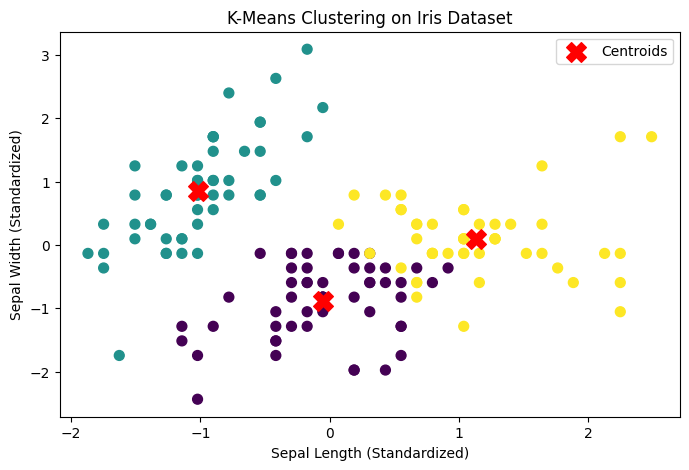

In [1]:

# K-Means Clustering using the Iris Dataset

# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 2: Load the dataset
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)

print("First 5 rows of the dataset:")
print(X.head())

# Step 3: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Create the K-Means model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Step 5: Fit the model and predict clusters
clusters = kmeans.fit_predict(X_scaled)

# Step 6: Add cluster labels to the dataset
X["Cluster"] = clusters

print("\nDataset with Cluster Labels:")
print(X.head(10))

# Step 7: Display cluster centers
print("\nCluster Centers:")
print(kmeans.cluster_centers_)

# Step 8: Visualize the clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")
plt.title("K-Means Clustering on Iris Dataset")
plt.legend()
plt.show()


In [2]:
import numpy as np
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix

y_true = iris.target

cm = confusion_matrix(y_true, clusters)
row_ind, col_ind = linear_sum_assignment(-cm)

accuracy = cm[row_ind, col_ind].sum() / len(y_true) * 100

print("Clustering Accuracy:", round(accuracy, 2), "%")

Clustering Accuracy: 83.33 %


Mall Customers Dataset:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  16                      81
2                  17                       6
3                  18                      77
4                  19                      40

Customers with Cluster Labels:
    Annual Income (k$)  Spending Score (1-100)  Cluster
0                   15                      39        1
1                   16                      81        2
2                   17                       6        1
3                   18                      77        2
4                   19                      40        1
5                   20                      76        2
6                   21                       6        1
7                   22                      94        2
8                   23                       3        1
9                   24                      72        2
10                  25                      14      

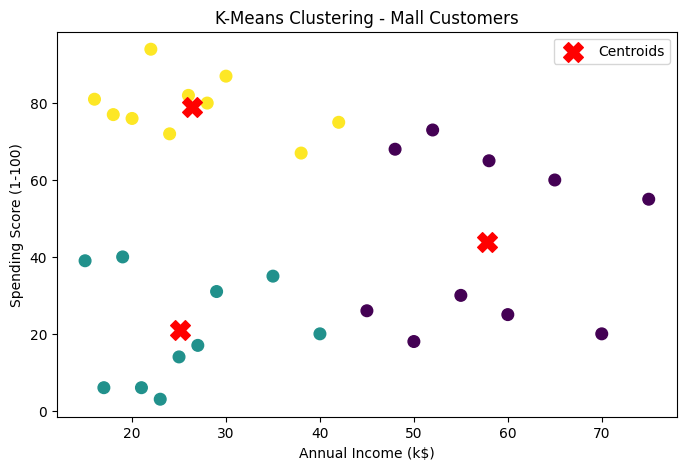

In [3]:

# K-Means Clustering using Mall Customers Dataset

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Step 2: Create a sample Mall Customers dataset
data = {
    'Annual Income (k$)': [
        15, 16, 17, 18, 19, 20, 21, 22, 23, 24,
        25, 26, 27, 28, 29, 30, 35, 38, 40, 42,
        45, 48, 50, 52, 55, 58, 60, 65, 70, 75
    ],
    'Spending Score (1-100)': [
        39, 81, 6, 77, 40, 76, 6, 94, 3, 72,
        14, 82, 17, 80, 31, 87, 35, 67, 20, 75,
        26, 68, 18, 73, 30, 65, 25, 60, 20, 55
    ]
}

df = pd.DataFrame(data)

# Step 3: Display dataset
print("Mall Customers Dataset:")
print(df.head())

# Step 4: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Step 5: Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Step 6: Add cluster labels
df['Cluster'] = clusters

print("\nCustomers with Cluster Labels:")
print(df)

# Step 7: Print cluster centers
print("\nCluster Centers:")
print(scaler.inverse_transform(kmeans.cluster_centers_))

# Step 8: Evaluate clustering using Silhouette Score
score = silhouette_score(X_scaled, clusters)
print("\nSilhouette Score:", round(score, 3))

# Step 9: Visualize clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=clusters,
    cmap='viridis',
    s=70
)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('K-Means Clustering - Mall Customers')
plt.legend()
plt.show()
